# Explore raw WAY-EEG-GAL recordings

Visual and quantitative checks of the raw files before building the pipeline. Subjects P1 and P2 are used for signal-level checks; AllLifts tables (small) are used for all 12 subjects.

In [1]:
import os
from pathlib import Path

# Run from the repo root regardless of where Jupyter was started.
if Path.cwd().name == "notebook":
    os.chdir("..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.signal

from eegtraj.data import raw_io

FIG_DIR = Path("output/data-baselines/data-inspection")
FIG_DIR.mkdir(parents=True, exist_ok=True)
FS_EEG = 500  # Hz, verified in dataset-notes
FS_EMG = 4000  # Hz
SUBJECTS_SIGNAL = ["P1", "P2"]
EVENTS = ["LEDOn", "tHandStart", "tFirstDigitTouch", "tLiftOff", "tReplace", "tBothReleased", "tHandStop", "LEDOff"]
EVENT_COLORS = dict(zip(EVENTS, plt.cm.tab10.colors))
pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

## Load data

All nine WS series for the two signal-level subjects, and the AllLifts tables for every subject.

In [2]:
ws = {s: {k: raw_io.load_ws(s, k) for k in raw_io.SERIES} for s in SUBJECTS_SIGNAL}
lifts = pd.concat([raw_io.load_alllifts(s) for s in raw_io.subjects()], ignore_index=True)
lifts["Subject"] = "P" + lifts["Part"].astype(int).astype(str)

names = ws["P1"]["S1"]["names"]
eeg_names, kin_names, emg_names = list(names["eeg"]), list(names["kin"]), list(names["emg"])
print({s: sum(len(ws[s][k]["win"]) for k in raw_io.SERIES) for s in SUBJECTS_SIGNAL}, "windows;", len(lifts), "AllLifts rows")

{'P1': 294, 'P2': 294} windows; 3528 AllLifts rows


## Example trials with event markers

Three lifts each from P1 and P2 (series S1). EEG channels: Fp1 (frontal), C3/Cz (central), T7 (temporal). EEG is shown after removing the window mean; no filtering. Event markers come from AllLifts.

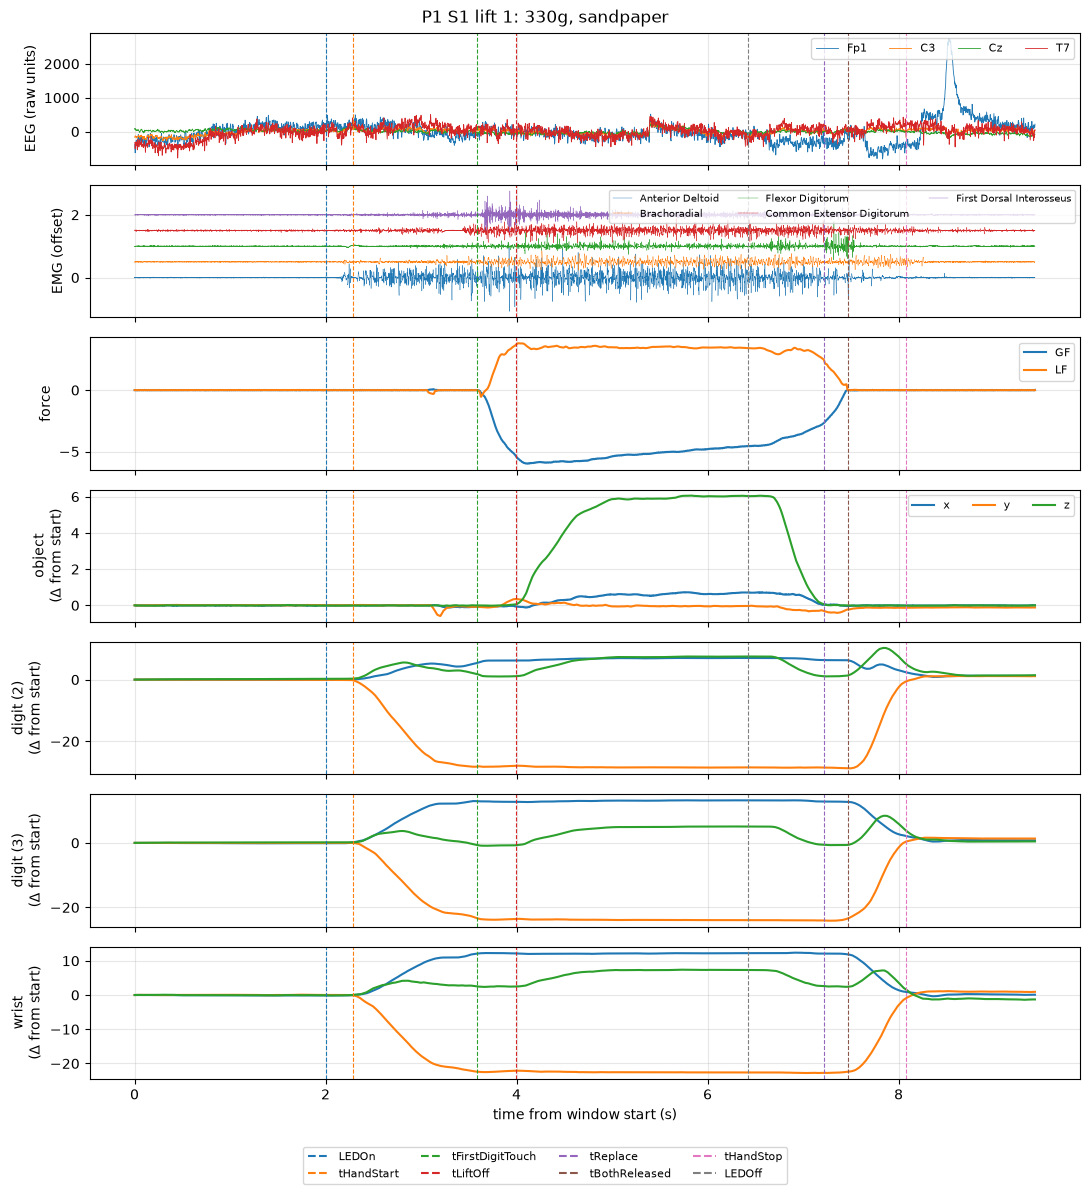

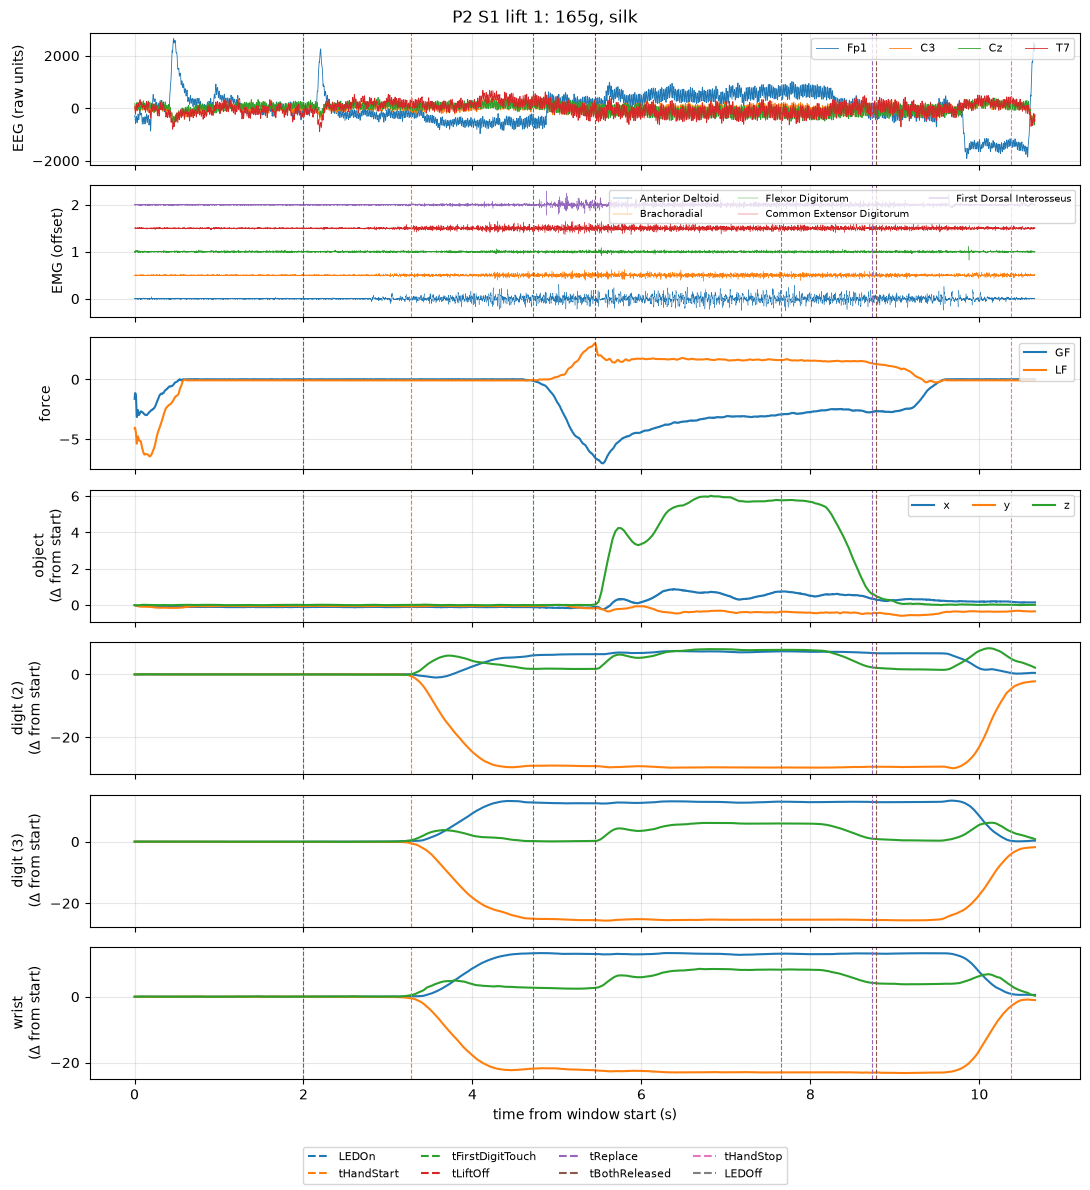

In [3]:
EEG_SHOW = ["Fp1", "C3", "Cz", "T7"]
SENSOR_LABEL = {1: "object", 2: "digit (2)", 3: "digit (3)", 4: "wrist"}

def plot_trial(subject, series, i):
    win = ws[subject][series]["win"][i]
    row = lifts[(lifts.Subject == subject) & (lifts.Run == int(series[1:])) & (lifts.Lift == i + 1)].iloc[0]
    t, t_emg = win["eeg_t"], win["emg_t"]
    fig, axes = plt.subplots(3 + 4, 1, figsize=(11, 12), sharex=True)
    for ch in EEG_SHOW:
        x = win["eeg"][:, eeg_names.index(ch)]
        axes[0].plot(t, x - x.mean(), lw=0.6, label=ch)
    axes[0].set_ylabel("EEG (raw units)")
    axes[0].legend(loc="upper right", ncol=4, fontsize=8)
    for j, m in enumerate(emg_names):
        axes[1].plot(t_emg, win["emg"][:, j] + j * 0.5, lw=0.3, label=m)
    axes[1].set_ylabel("EMG (offset)")
    axes[1].legend(loc="upper right", ncol=3, fontsize=7)
    gf = win["kin"][:, kin_names.index("GF")]
    lf = win["kin"][:, kin_names.index("LF")]
    axes[2].plot(t, gf, label="GF"); axes[2].plot(t, lf, label="LF")
    axes[2].set_ylabel("force"); axes[2].legend(loc="upper right", fontsize=8)
    for k, sensor in enumerate((1, 2, 3, 4)):
        p = win["kin"][:, raw_io.position_columns(kin_names, sensor)]
        for a, axis in enumerate(raw_io.AXES):
            axes[3 + k].plot(t, p[:, a] - p[0, a], label=axis)
        axes[3 + k].set_ylabel(f"{SENSOR_LABEL[sensor]}\n(Δ from start)")
    axes[3].legend(loc="upper right", ncol=3, fontsize=8)
    for ax in axes:
        for ev in EVENTS:
            ax.axvline(row[ev], color=EVENT_COLORS[ev], lw=0.8, ls="--")
    handles = [plt.Line2D([], [], color=EVENT_COLORS[e], ls="--") for e in EVENTS]
    fig.legend(handles, EVENTS, loc="lower center", ncol=4, fontsize=8)
    axes[-1].set_xlabel("time from window start (s)")
    fig.suptitle(f"{subject} {series} lift {i + 1}: {win['weight_id']}, {win['surf_id']}")
    fig.tight_layout(rect=(0, 0.04, 1, 1))
    return fig

for subject in SUBJECTS_SIGNAL:
    for i in (0, 10, 20):
        fig = plot_trial(subject, "S1", i)
        fig.savefig(FIG_DIR / f"example_trial_{subject}_S1_lift{i + 1}.png")
        if i != 0:
            plt.close(fig)
plt.show()

## Trial durations and event intervals

From AllLifts for all 12 subjects. Intervals in seconds.

,count,min,1%,50%,99%,max
window_s,588.0,8.230,8.294,9.274,11.877,12.386
LED->HandStart,3528.0,-0.366,0.251,0.414,2.494,7.854
reach (HandStart->FirstTouch),3528.0,0.400,0.424,0.998,1.685,2.230
touch->LiftOff,3528.0,0.064,0.112,0.422,1.434,3.048
hold (LiftOff->Replace),3528.0,1.538,2.786,3.212,4.118,4.988
Replace->HandStop,3528.0,0.512,0.612,0.964,1.763,2.856
movement (HandStart->HandStop),3528.0,4.028,4.342,5.650,8.190,10.360
HandStop->window end,588.0,0.024,0.074,1.324,1.733,1.802


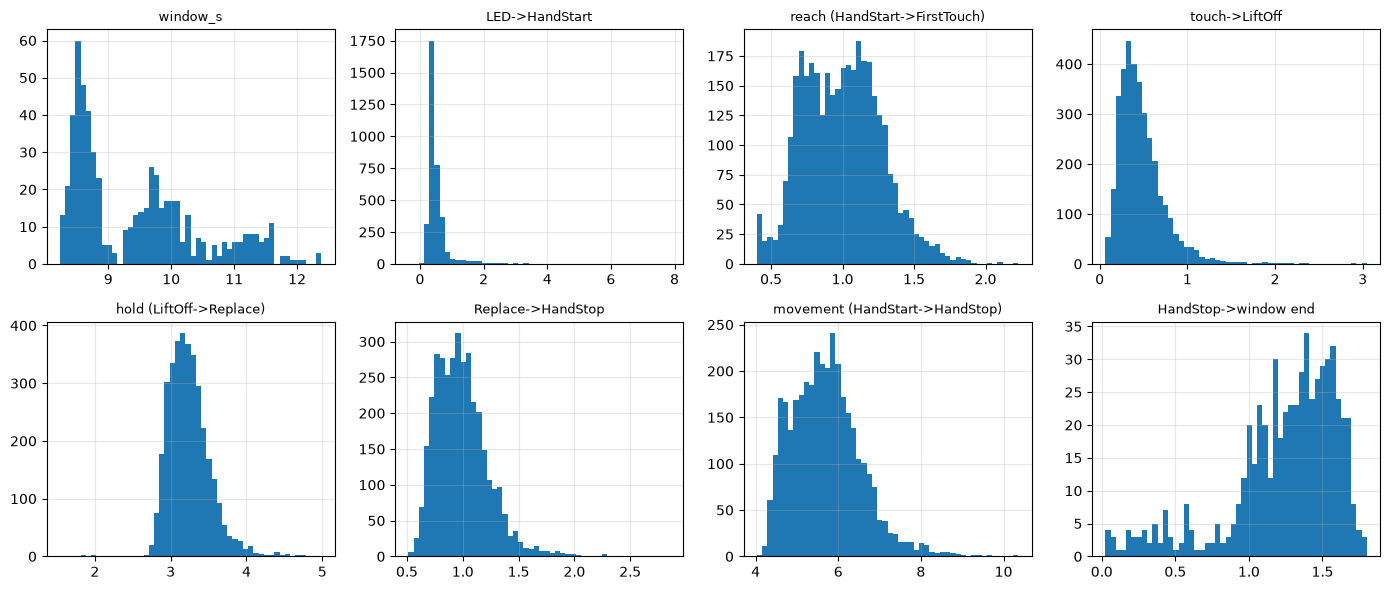

In [4]:
iv = pd.DataFrame({
    "Subject": lifts.Subject,
    "window_s": np.nan,
    "LED->HandStart": lifts.tHandStart - lifts.LEDOn,
    "reach (HandStart->FirstTouch)": lifts.tFirstDigitTouch - lifts.tHandStart,
    "touch->LiftOff": lifts.tLiftOff - lifts.tFirstDigitTouch,
    "hold (LiftOff->Replace)": lifts.tReplace - lifts.tLiftOff,
    "Replace->HandStop": lifts.tHandStop - lifts.tReplace,
    "movement (HandStart->HandStop)": lifts.tHandStop - lifts.tHandStart,
    "HandStop->window end": np.nan,
})
# Window length comes from the WS files, available for the signal-level subjects.
for s in SUBJECTS_SIGNAL:
    lens = np.concatenate([[w["eeg_t"][-1] for w in ws[s][k]["win"]] for k in raw_io.SERIES])
    m = (iv.Subject == s).to_numpy()
    iv.loc[m, "window_s"] = lens
    iv.loc[m, "HandStop->window end"] = lens - lifts.loc[m, "tHandStop"].to_numpy()

cols = [c for c in iv.columns if c != "Subject"]
display(iv[cols].describe(percentiles=[0.01, 0.5, 0.99]).T[["count", "min", "1%", "50%", "99%", "max"]])

fig, axes = plt.subplots(2, 4, figsize=(14, 6))
for ax, c in zip(axes.ravel(), cols):
    ax.hist(iv[c].dropna(), bins=50)
    ax.set_title(c, fontsize=9)
fig.tight_layout()
fig.savefig(FIG_DIR / "event_intervals_all_subjects.png")
plt.show()

In [5]:
per_subject = iv.groupby("Subject", sort=False)[["reach (HandStart->FirstTouch)", "hold (LiftOff->Replace)", "movement (HandStart->HandStop)"]].median()
per_subject.loc[raw_io.subjects()]

,reach (HandStart->FirstTouch),hold (LiftOff->Replace),movement (HandStart->HandStop)
Subject,,,
P1,0.718,3.018,4.731
P2,1.170,3.394,6.252
P3,0.717,2.922,4.634
P4,0.748,3.227,5.262
P5,1.064,3.174,5.640
P6,1.025,3.261,5.877
P7,1.167,3.473,6.320
P8,0.804,3.054,5.021
P9,1.088,3.141,5.752


## Flat or noisy EEG channels

Per series, per channel: robust amplitude (median absolute deviation after a 1 Hz high-pass, zero-phase; inspection only) computed on the HS continuous recording. A channel is flagged **flat** if its MAD is below 10% of the median MAD across channels in that series, and **noisy** if above 5x. P1 and P2 only; all subjects will be checked during the cache build.

In [6]:
FLAT_RATIO, NOISY_RATIO = 0.1, 5.0
sos_hp = scipy.signal.butter(4, 1.0, btype="highpass", fs=FS_EEG, output="sos")

rows = []
for s in SUBJECTS_SIGNAL:
    for k in list(raw_io.SERIES) + ["ST"]:
        hs = raw_io.load_hs(s, k)
        x = scipy.signal.sosfiltfilt(sos_hp, hs["eeg"]["sig"].astype(np.float64), axis=0)
        mad = np.median(np.abs(x - np.median(x, axis=0)), axis=0)
        ratio = mad / np.median(mad)
        for ch, m, r in zip(eeg_names, mad, ratio):
            rows.append({"Subject": s, "Series": k, "channel": ch, "mad": m, "ratio": r})
amp = pd.DataFrame(rows)
amp["flag"] = np.select([amp.ratio < FLAT_RATIO, amp.ratio > NOISY_RATIO], ["flat", "noisy"], "")
flagged = amp[amp.flag != ""]
print(f"{len(flagged)} flagged channel-series out of {len(amp)}")
display(flagged)

5 flagged channel-series out of 640


,Subject,Series,channel,mad,ratio,flag
324,P2,S1,Fz,7.585,0.066,flat
356,P2,S2,Fz,7.487,0.073,flat
388,P2,S3,Fz,7.669,0.081,flat
420,P2,S4,Fz,7.320,0.083,flat
452,P2,S5,Fz,7.304,0.088,flat


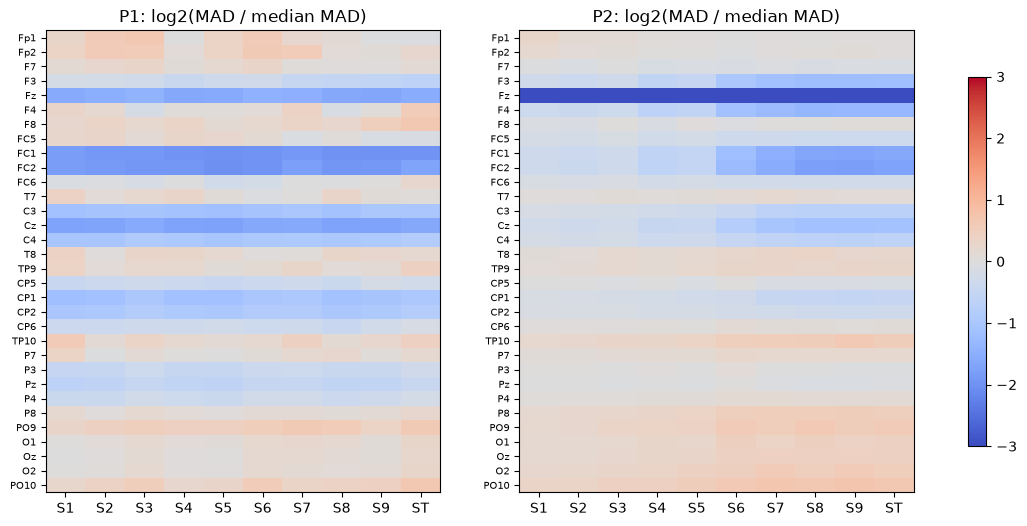

Median high-passed MAD over channels (raw units): {'P1': 55.9, 'P2': 83.0}


In [7]:
fig, axes = plt.subplots(1, len(SUBJECTS_SIGNAL), figsize=(14, 6))
for ax, s in zip(axes, SUBJECTS_SIGNAL):
    piv = amp[amp.Subject == s].pivot(index="channel", columns="Series", values="ratio").loc[eeg_names]
    im = ax.imshow(np.log2(piv.to_numpy()), aspect="auto", cmap="coolwarm", vmin=-3, vmax=3)
    ax.set_yticks(range(len(eeg_names)), eeg_names, fontsize=7)
    ax.set_xticks(range(piv.shape[1]), piv.columns)
    ax.set_title(f"{s}: log2(MAD / median MAD)")
    ax.grid(False)
fig.colorbar(im, ax=axes, shrink=0.8)
fig.savefig(FIG_DIR / "eeg_channel_amplitude_P1_P2.png")
plt.show()
print("Median high-passed MAD over channels (raw units):", amp.groupby("Subject").mad.median().round(1).to_dict())

## Sampling-rate consistency and EEG/kinematics alignment

Checks per window: EEG and kinematics share the same number of samples, EMG has exactly 8x as many, and the time vectors step at 1/500 s and 1/4000 s. Then the hand-start event is compared with movement onset detected from wrist speed, and lift-off with the object's vertical displacement, to confirm that event times and kinematics share one time base.

In [8]:
checks = []
for s in SUBJECTS_SIGNAL:
    for k in raw_io.SERIES:
        for w in ws[s][k]["win"]:
            checks.append({
                "same_len_eeg_kin": len(w["eeg"]) == len(w["kin"]) == len(w["eeg_t"]),
                "emg_8x": len(w["emg"]) == 8 * len(w["eeg"]),
                "eeg_dt_ok": np.allclose(np.diff(w["eeg_t"]), 1 / FS_EEG),
                "emg_dt_ok": np.allclose(np.diff(w["emg_t"]), 1 / FS_EMG),
                "same_end_time": np.isclose(w["eeg_t"][-1], w["emg_t"][-1]),
            })
pd.DataFrame(checks).agg(["sum", "count"])

,same_len_eeg_kin,emg_8x,eeg_dt_ok,emg_dt_ok,same_end_time
sum,588,588,588,588,588
count,588,588,588,588,588


In [9]:
SPEED_THRESH_FRAC = 0.05  # reach onset: last sample before the reach speed peak with speed below 5% of that peak
LIFT_THRESH = 0.2  # object z rise (kin units) above its height at first touch that marks lift-off
STATIC_REACH = 5.0  # hand displacement (kin units) during [tHandStart, tFirstDigitTouch] below which the reach is missing
sos_lp = scipy.signal.butter(2, 10, fs=FS_EEG, output="sos")

def kin_events(win, row):
    """Kinematic reach onset (wrist speed) and lift-off (object height), in window time (s)."""
    t = win["eeg_t"]
    wrist = scipy.signal.sosfiltfilt(sos_lp, win["kin"][:, raw_io.position_columns(kin_names, 4)], axis=0)
    speed = np.linalg.norm(np.gradient(wrist, t, axis=0), axis=1)
    # The reach is the largest wrist speed peak between 0.5 s after the window start and first touch.
    seg = (t > 0.5) & (t <= row.tFirstDigitTouch)
    i_peak = np.flatnonzero(seg)[np.argmax(speed[seg])]
    below = np.flatnonzero(speed[:i_peak] < SPEED_THRESH_FRAC * speed[i_peak])
    onset = t[below[-1]] if below.size else np.nan
    obj_z = win["kin"][:, raw_io.position_columns(kin_names, 1)[2]]
    after = t >= row.tFirstDigitTouch
    z0 = obj_z[after][0]
    lift = t[after][np.argmax(obj_z[after] - z0 > LIFT_THRESH)]
    reach = (t >= row.tHandStart) & (t <= row.tFirstDigitTouch)
    reach_disp = np.linalg.norm(np.ptp(wrist[reach], axis=0))
    return onset, lift, speed[i_peak], reach_disp

rows = []
for s in SUBJECTS_SIGNAL:
    al = lifts[lifts.Subject == s]
    for k in raw_io.SERIES:
        sub = al[al.Run == int(k[1:])].reset_index(drop=True)
        for i, w in enumerate(ws[s][k]["win"]):
            onset, lift, vmax, disp = kin_events(w, sub.iloc[i])
            rows.append({"Subject": s, "Series": k, "Lift": i + 1,
                         "onset_minus_tHandStart": onset - sub.tHandStart[i],
                         "lift_minus_tLiftOff": lift - sub.tLiftOff[i], "peak_wrist_speed": vmax,
                         "tPeakVelHandReach": sub.tPeakVelHandReach[i], "reach_disp": disp,
                         "LED_to_HandStart": sub.tHandStart[i] - sub.LEDOn[i]})
align = pd.DataFrame(rows)
align["static_reach"] = align.reach_disp < STATIC_REACH
ok = ~align.static_reach
display(align[ok].groupby("Subject")[["onset_minus_tHandStart", "lift_minus_tLiftOff"]]
        .describe(percentiles=[0.05, 0.5, 0.95]).T.round(3))
print("corr(peak wrist speed, tPeakVelHandReach):",
      {s: round(np.corrcoef(g.peak_wrist_speed, g.tPeakVelHandReach)[0, 1], 3) for s, g in align.groupby("Subject")})

Subject                            P1       P2
onset_minus_tHandStart count  293.000  276.000
                       mean    -0.066   -0.364
                       std      0.320    0.786
                       min     -2.156   -2.604
                       5%      -0.022   -2.415
                       50%     -0.012   -0.044
                       95%     -0.006   -0.022
                       max      0.000   -0.014
lift_minus_tLiftOff    count  294.000  276.000
                       mean     0.053    0.043
                       std      0.011    0.070
                       min      0.026   -0.430
                       5%       0.032    0.028
                       50%      0.052    0.054
                       95%      0.070    0.086
                       max      0.092    0.108

corr(peak wrist speed, tPeakVelHandReach): {'P1': np.float64(0.991), 'P2': np.float64(0.539)}


### Lifts where the hand does not move between `tHandStart` and first touch

In some lifts the wrist barely moves during the labeled reach interval: the hand reached the object before the labeled `tHandStart`, so that event marks a later, small movement. These lifts need either exclusion or a kinematically derived onset (protocol decision D2).

In [10]:
static = align[align.static_reach]
print(static.groupby(["Subject", "Series"]).size().rename("n_static_reach").to_string())
display(static[["Subject", "Series", "Lift", "reach_disp", "LED_to_HandStart", "onset_minus_tHandStart"]].round(2))
print("LED->HandStart, static vs normal (median s):",
      static.LED_to_HandStart.median().round(2), "vs", align[ok].LED_to_HandStart.median().round(2))

Subject  Series
P2       S1         5
         S2        11
         S3         1
         S5         1


,Subject,Series,Lift,reach_disp,LED_to_HandStart,onset_minus_tHandStart
300,P2,S1,7,0.59,2.59,-1.24
302,P2,S1,9,0.39,2.74,-1.20
304,P2,S1,11,0.83,2.22,-1.30
315,P2,S1,22,1.62,2.55,-1.21
317,P2,S1,24,0.24,2.58,-1.33
323,P2,S2,2,1.04,2.33,-1.33
328,P2,S2,7,0.85,2.07,-1.22
330,P2,S2,9,0.75,2.42,-1.23
338,P2,S2,17,0.81,2.59,-1.47
343,P2,S2,22,0.61,2.59,-1.28


LED->HandStart, static vs normal (median s): 2.5 vs 0.46


In [11]:
# Cheap proxy for all subjects: a long LED->HandStart delay. Not a substitute for the kinematic check.
LATE_HANDSTART_S = 2.0
late = lifts.assign(late=(lifts.tHandStart - lifts.LEDOn) > LATE_HANDSTART_S).groupby("Subject").late.sum()
late.loc[raw_io.subjects()].rename(f"lifts with LED->HandStart > {LATE_HANDSTART_S} s")

Subject
P1      0
P2     16
P3      0
P4      0
P5      0
P6      1
P7     34
P8      0
P9      1
P10     2
P11     0
P12     1
Name: lifts with LED->HandStart > 2.0 s, dtype: int64

## Trajectory stereotypy

Wrist trajectories of all lifts except those with a static labeled reach, aligned to `tHandStart`, re-centered at the hand-start position, from 0.5 s before to 4 s after hand start. If the trajectories overlap tightly, a template (mean trajectory vs time since onset) already predicts much of the variance; this motivates the template and stereotypy-floor baselines.

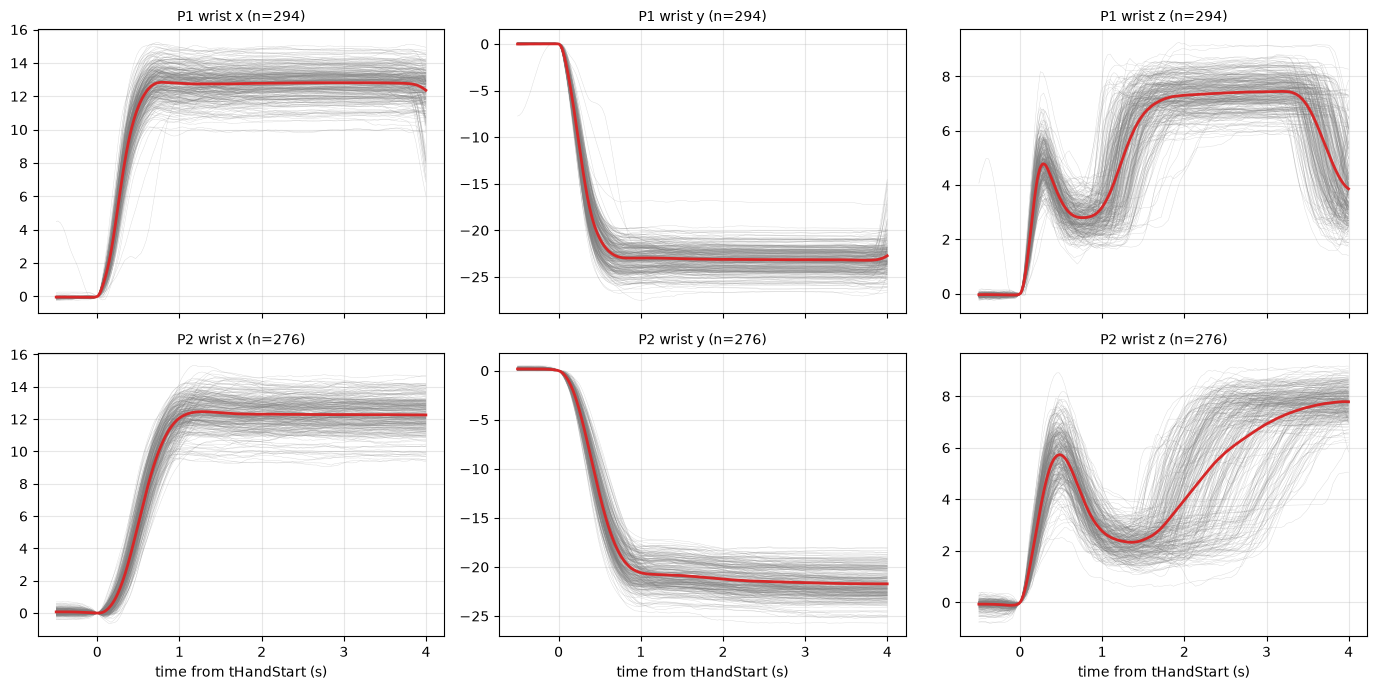

In-sample variance explained by the mean trajectory, per axis (x, y, z): {'P1': [0.964, 0.974, 0.887], 'P2': [0.964, 0.973, 0.796]}


In [12]:
T_PRE_S, T_POST_S = 0.5, 4.0
grid = np.arange(-T_PRE_S, T_POST_S, 1 / FS_EEG)

def aligned_wrist(subject):
    out, conds = [], []
    al = lifts[lifts.Subject == subject]
    for k in raw_io.SERIES:
        sub = al[al.Run == int(k[1:])].reset_index(drop=True)
        for i, w in enumerate(ws[subject][k]["win"]):
            t = w["eeg_t"] - sub.tHandStart[i]
            p = w["kin"][:, raw_io.position_columns(kin_names, 4)]
            p0 = np.array([np.interp(0.0, t, p[:, a]) for a in range(3)])
            out.append(np.stack([np.interp(grid, t, p[:, a] - p0[a], left=np.nan, right=np.nan) for a in range(3)], axis=1))
            conds.append(w["weight_id"])
    return np.array(out), np.array(conds)

fig, axes = plt.subplots(len(SUBJECTS_SIGNAL), 3, figsize=(14, 7), sharex=True)
stereo = {}
for r, s in enumerate(SUBJECTS_SIGNAL):
    traj, _ = aligned_wrist(s)
    # Drop lifts whose labeled reach interval has no movement (see the alignment section).
    traj = traj[~align[align.Subject == s].static_reach.to_numpy()]
    mean = np.nanmean(traj, axis=0)
    for a, axis in enumerate(raw_io.AXES):
        ax = axes[r, a]
        ax.plot(grid, traj[:, :, a].T, color="0.5", lw=0.3, alpha=0.3)
        ax.plot(grid, mean[:, a], color="C3", lw=2)
        ax.set_title(f"{s} wrist {axis} (n={len(traj)})", fontsize=10)
    # Fraction of per-trial variance explained by the subject's mean trajectory (in-sample, illustrative only).
    valid = ~np.isnan(traj).any(axis=(0, 2))
    resid = traj[:, valid] - mean[valid]
    centered = traj[:, valid] - traj[:, valid].mean(axis=1, keepdims=True)
    stereo[s] = 1 - np.nansum(resid ** 2, axis=(0, 1)) / np.nansum(centered ** 2, axis=(0, 1))
for ax in axes[-1]:
    ax.set_xlabel("time from tHandStart (s)")
fig.tight_layout()
fig.savefig(FIG_DIR / "wrist_trajectory_stereotypy_P1_P2.png")
plt.show()
print("In-sample variance explained by the mean trajectory, per axis (x, y, z):",
      {s: np.round(v, 3).tolist() for s, v in stereo.items()})